# Numerical Calculus: Accuracy, Resolution, and Computational Cost

**Course:** Math Concepts for Developers · **Repository owner:** mimindss1-bot

## 1. Problem formulation
How can we choose a numerical method and sampling resolution to estimate rates of change and accumulated quantities accurately?

This report compares three derivative methods (forward, central, and Richardson) and three definite-integration methods (left rectangles, trapezoids, and midpoints). A synthetic mechanics example estimates velocity from position and distance from velocity. Analytical benchmarks make numerical error measurable.

**Objectives:** derive and implement the formulas, validate against independent known answers, measure convergence, compare function-evaluation budgets, quantify noise amplification, and investigate failed assumptions.

**Hypotheses:** for sufficiently smooth functions, central differences converge faster than forward differences, Richardson cancellation increases the truncation order further, and trapezoids/midpoints generally outperform left rectangles. These gains may disappear with tiny floating-point steps, measurement noise, boundary restrictions, or insufficient smoothness.

**Scope and assumptions:** uniform grids, finite intervals, scalar real outputs, float64 arithmetic. Smooth deterministic benchmarks are the baseline; a separate seeded Gaussian-noise experiment and a singular-endpoint example explicitly relax those assumptions. Sampled-value counts measure cost rather than wall-clock time. This is a reproducible algorithm analysis with a controlled practical application, not a claim of a new numerical algorithm.

**Report map:** Sections 2–3 derive the methods; Section 4 validates them; Sections 5–6 compare accuracy and cost; Section 7 applies them to motion; Section 8 tests limitations; Sections 9–11 summarize evidence, conclusions, and sources.


In [1]:
from pathlib import Path
import csv
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

OUTPUT = Path("results")
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print("Python:", platform.python_version())
print("NumPy:", np.__version__, "Matplotlib:", matplotlib.__version__)
print("float64 machine epsilon:", np.finfo(np.float64).eps)


def save_rows(filename, rows):
    with (OUTPUT / filename).open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def finish_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT / name, dpi=160, bbox_inches="tight")
    plt.show()

from analysis_tools import observed_order


Python: 3.14.6
NumPy: 2.4.6 Matplotlib: 3.11.0
float64 machine epsilon: 2.220446049250313e-16


## 2. Mathematical derivation: differentiation
Taylor expansion about $x$ gives
$$f(x+h)=f(x)+hf'(x)+\frac{h^2}{2}f''(x)+O(h^3).$$
Subtracting $f(x)$ and dividing by $h$ yields
$$D_f(h)=\frac{f(x+h)-f(x)}h=f'(x)+\frac h2 f''(x)+O(h^2).$$
Expanding at both $+h$ and $-h$ and subtracting cancels the even powers:
$$D_c(h)=\frac{f(x+h)-f(x-h)}{2h}=f'(x)+\frac{h^2}{6}f^{(3)}(x)+O(h^4).$$
The displayed central remainder assumes sufficient smoothness for those Taylor terms. Bounded third derivatives already give an $O(h^2)$ truncation bound. See the general differentiation formulas in reference [1].

Finite precision introduces another effect: subtracting nearly equal function values loses relative precision. A simplified absolute-error model is $C_t h^p+C_r\epsilon/h$, with method- and function-dependent constants. Balancing terms suggests scales $\sqrt{\epsilon}$ for forward differences and $\epsilon^{1/3}$ for central differences when problem scales are near one. These are guidelines, not universal optimal steps. Reference [3] documents machine epsilon.

Both methods use two scalar function evaluations per estimate. Central differences require samples on both sides of the point and may be unsuitable at a domain boundary. Section 5.1 extends the comparison with a higher-order Richardson formula. Automatic and symbolic differentiation are alternatives outside this implementation.


In [2]:
from numerical_methods import forward_difference, central_difference

## 3. Mathematical derivation: integration
For $n$ intervals on $[a,b]$, let $h=(b-a)/n$ and $x_i=a+ih$. Replacing each interval by its left endpoint height gives
$$L_n=h\sum_{i=0}^{n-1}f(x_i).$$
If $|f'|\le M_1$, each interval has error at most $M_1h^2/2$; summing gives $|I-L_n|\le (b-a)M_1h/2$ for $a<b$.

Integrating the straight line joining consecutive endpoints gives the composite trapezoid rule:
$$T_n=h\left[\frac{f(a)+f(b)}2+\sum_{i=1}^{n-1}f(x_i)\right].$$
For $f\in C^2[a,b]$ and $|f''|\le M_2$,
$$|I-T_n|\le\frac{b-a}{12}h^2 M_2.$$
Reference [2] supplies the trapezoid error formula. The integral is signed, not always geometrical area.

Rectangles use $n$ sampled values and trapezoids $n+1$. Both implementations take $O(n)$ work and $O(n)$ array memory. Their fair comparison therefore includes function-evaluation counts, not only interval counts. We count sampled scalar values even when NumPy evaluates an array in a single call. Simpson and adaptive quadrature are useful alternatives but outside the chosen scope.


### Midpoint rule
Sampling at each interval center gives
$$M_n=h\sum_{i=0}^{n-1}f\left(a+(i+\tfrac12)h\right).$$
A Taylor expansion about the center cancels the integral of the odd linear term. The local error is bounded by $M_2h^3/24$, giving a global bound $|I-M_n|\le (b-a)M_2h^2/24$ for twice continuously differentiable functions on $a<b$. Midpoints use n sampled values, like left rectangles. Unlike trapezoids, they do not require function values at the endpoints; this matters if those endpoints are outside the function's evaluation domain. A second-order formula does not ensure its smooth error bound applies to singular endpoints.


In [3]:
from numerical_methods import left_rectangle, trapezoid, midpoint

## 4. Validation before experiments
Checks include exactness for constants and affine functions, a known quadratic integral, reversed and zero-length bounds, and rejected invalid inputs. Assertions test independently known results rather than reimplementing the formulas as tests. No library quadrature routine is used as the only reference.


The algorithms live in `numerical_methods.py` so the notebook and standalone unit tests exercise the same implementation. Invalid steps, non-finite samples, incompatible output shapes, and unresolvable sampling grids are rejected explicitly. Integration callables must accept NumPy arrays; scalar constant outputs are supported. Run `python -m unittest discover -s tests -v` for independent regression checks.

The standalone suite contains 34 tests, including fourth-order cancellation, second-order midpoint error, empirical-order regression, variance propagation, endpoint singularities, and rejection of incomplete or invalid report artifacts. The isolated verifier executes all 14 code cells in a fresh kernel, checks seven embedded figures and eleven regenerated CSV tables, and exports the HTML report only after success. GitHub Actions repeats these checks on Python 3.12 and 3.14; see the repository Actions tab for the actual run status.

In [4]:
def expect_value_error(action):
    try:
        action()
    except ValueError:
        return
    raise AssertionError("Expected ValueError")


for method in (forward_difference, central_difference):
    assert np.isclose(method(lambda x: 3*x + 2, 1.0, 0.01), 3)
    assert np.isclose(method(lambda x: 7, 2.0, 0.01), 0)
    expect_value_error(lambda: method(np.sin, 1.0, 0))
    expect_value_error(lambda: method(np.sin, 1.0, 1e-30))
assert np.isclose(central_difference(lambda x: x*x, 2.0, 0.01), 4)
for method in (left_rectangle, trapezoid):
    assert np.isclose(method(lambda x: 3, -1, 2, 10), 9)
    assert method(np.exp, 2, 2, 10) == 0
    expect_value_error(lambda: method(np.exp, 0, 1, 0))
    expect_value_error(lambda: method(np.exp, 0, 1, 2.5))
assert np.isclose(trapezoid(lambda x: 2*x+1, 0, 1, 5), 2)
assert np.isclose(trapezoid(lambda x: x*x, 0, 1, 1000), 1/3, atol=2e-7, rtol=0)
assert np.isclose(trapezoid(np.exp, 1, 0, 100), -trapezoid(np.exp, 0, 1, 100))
assert np.isclose(left_rectangle(lambda x: x, 1, 0, 100), -0.505)
print("All validation checks passed.")


All validation checks passed.


## 5. Derivative experiment: resolution and roundoff
Benchmarks are $e^x$ at 1, $\sin x$ at 0.7, and $x^3$ at 1.3. Their nonzero reference derivatives are $e$, $\cos(0.7)$, and $3(1.3)^2$. Each method uses the same 100 logarithmically spaced steps between $10^{-1}$ and $10^{-15}$. We report absolute error; no random sampling is involved.

The reference values are analytical expressions evaluated in float64, not arbitrary-precision truth. Errors near machine precision therefore reflect both approximation and reference rounding. Zero measured error does not prove mathematical exactness.


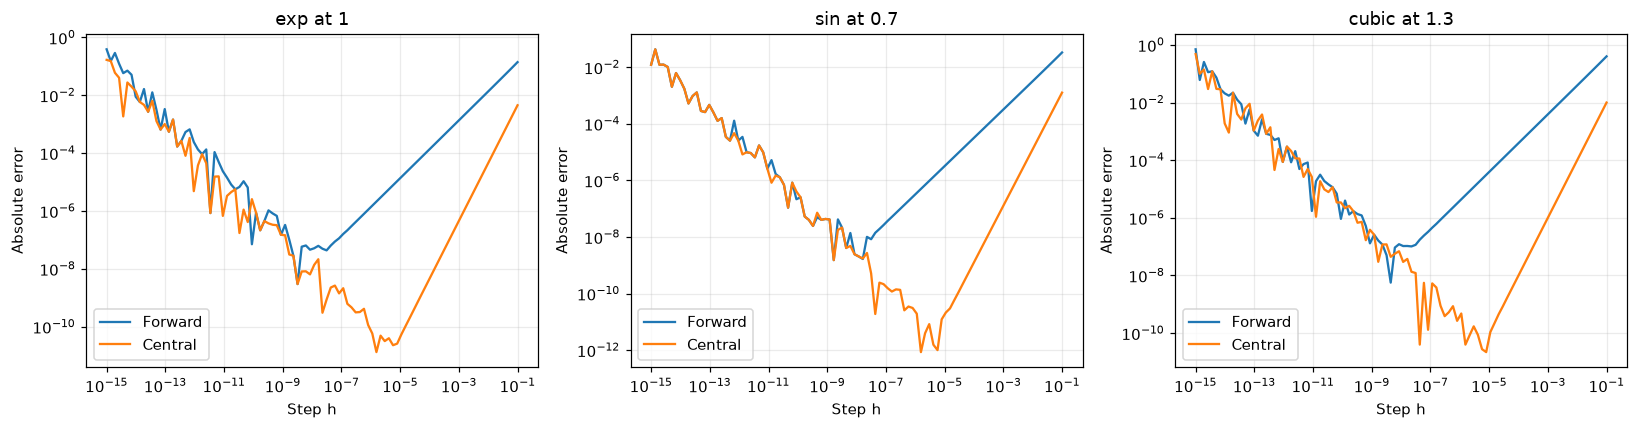

exp at 1        Forward  best sampled h=3.20e-09, error=2.97e-09
exp at 1        Central  best sampled h=1.56e-06, error=1.32e-11
sin at 0.7      Forward  best sampled h=1.67e-09, error=1.52e-09
sin at 0.7      Central  best sampled h=1.56e-06, error=8.52e-13
cubic at 1.3    Forward  best sampled h=4.43e-09, error=5.66e-09
cubic at 1.3    Central  best sampled h=7.92e-06, error=2.20e-11


In [5]:
derivative_cases = [
    ("exp at 1", np.exp, 1.0, np.exp(1.0)),
    ("sin at 0.7", np.sin, 0.7, np.cos(0.7)),
    ("cubic at 1.3", lambda x: x**3, 1.3, 3*1.3**2),
]
derivative_methods = [("Forward", forward_difference), ("Central", central_difference)]
steps = np.logspace(-1, -15, 100)
derivative_rows = []
best_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, function, point, reference) in zip(axes, derivative_cases):
    for method_name, method in derivative_methods:
        errors = np.array([abs(method(function, point, h) - reference) for h in steps])
        for h, error in zip(steps, errors):
            derivative_rows.append(dict(case=name, method=method_name, step=h, absolute_error=error))
        best = int(np.argmin(errors))
        best_rows.append(dict(case=name, method=method_name, step=steps[best], error=errors[best]))
        # Omit zero errors from logarithmic axes instead of inventing a positive error.
        ax.loglog(steps, np.where(errors > 0, errors, np.nan), label=method_name)
    ax.set(title=name, xlabel="Step h", ylabel="Absolute error")
    ax.legend()
finish_figure(fig, "derivative_errors.png")
save_rows("derivative_errors.csv", derivative_rows)
for row in best_rows:
    print(f"{row['case']:15} {row['method']:8} best sampled h={row['step']:.2e}, error={row['error']:.2e}")


### Measuring derivative convergence
If $E(h)\approx Ch^p$, fitting $\log E$ against $\log h$ estimates $p$. We choose $10^{-2}$ through $10^{-4}$ in advance to emphasize truncation rather than tiny-step roundoff. These fits are descriptive evidence on the selected range, not proofs or confidence intervals.


In [6]:
order_rows = []
fit_steps = np.logspace(-2, -4, 15)
for name, function, point, reference in derivative_cases:
    for method_name, method in derivative_methods:
        errors = np.array([abs(method(function, point, h) - reference) for h in fit_steps])
        slope = observed_order(fit_steps, errors)
        order_rows.append(dict(kind="derivative", case=name, method=method_name, measured_order=slope))
        print(f"{name:15} {method_name:8} estimated order={slope:.3f}")


exp at 1        Forward  estimated order=1.001
exp at 1        Central  estimated order=2.000
sin at 0.7      Forward  estimated order=1.001
sin at 0.7      Central  estimated order=2.000
cubic at 1.3    Forward  estimated order=1.000
cubic at 1.3    Central  estimated order=2.000


### 5.1 Richardson extrapolation: a fourth-order alternative
Write $D_c(h)=f'(x)+c_2h^2+c_4h^4+O(h^6)$. Combining two resolutions removes the $h^2$ term:
$$D_R(h)=\frac{4D_c(h/2)-D_c(h)}3=f'(x)-\frac{h^4}{480}f^{(5)}(x)+O(h^6).$$
This expansion assumes enough smoothness. Four sampled values are required instead of two. For cubic and quartic polynomials the truncation terms cancel exactly in exact arithmetic, so a measured convergence order would be misleading.

For exp and sin we fit fourth-order convergence on a coarser, preselected range h∈[0.03,0.3], before rounding dominates. The graph compares error for exp at 1; one Richardson estimate costs twice as many sampled values as a forward or central estimate. The extra precision is therefore not free.

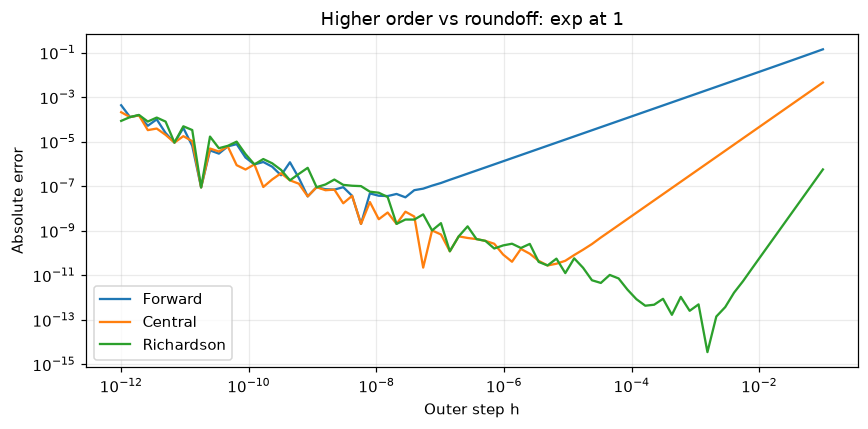

exp at 1: Richardson estimated order=4.001
sin at 0.7: Richardson estimated order=3.999


In [7]:
from numerical_methods import richardson_difference
richardson_steps = np.logspace(-1, -12, 80)
richardson_rows = []
fig, ax = plt.subplots(figsize=(8, 4))
for label, method in derivative_methods + [("Richardson", richardson_difference)]:
    errors = np.array([abs(method(np.exp, 1, h)-np.e) for h in richardson_steps])
    ax.loglog(richardson_steps, np.where(errors > 0, errors, np.nan), label=label)
    richardson_rows.extend(dict(method=label, step=h, absolute_error=e)
                           for h, e in zip(richardson_steps, errors))
ax.set(xlabel="Outer step h", ylabel="Absolute error", title="Higher order vs roundoff: exp at 1")
ax.legend()
finish_figure(fig, "richardson_errors.png")
save_rows("richardson_errors.csv", richardson_rows)
for name, function, point, reference in derivative_cases[:2]:
    hs = np.logspace(np.log10(0.3), np.log10(0.03), 15)
    errors = [abs(richardson_difference(function, point, h)-reference) for h in hs]
    slope = observed_order(hs, errors)
    assert 3.9 < slope < 4.1
    order_rows.append(dict(kind="derivative", case=name, method="Richardson", measured_order=slope))
    print(f"{name}: Richardson estimated order={slope:.3f}")
assert np.isclose(richardson_difference(lambda x: x**3, 1, 0.125), 3)


## 6. Integration experiment and sampling cost
Benchmarks are x² on [0,1], exp(x) on [0,1], and sin(x) on [0,π], with references 1/3, e−1, and 2. We use powers of two from 8 to 4096 intervals. Every experiment records its approximation, error, and number of sampled values. Theoretical error bounds are also checked using bounds on the first and second derivatives.


Midpoint estimates are now included on the same benchmark grids. The cost axis counts n samples for rectangles/midpoints and n+1 for trapezoids.

quadratic  Left       estimated order=1.000; final error=1.221e-04
quadratic  Trapezoid  estimated order=2.000; final error=9.934e-09
quadratic  Midpoint   estimated order=2.000; final error=4.967e-09
exp        Left       estimated order=1.000; final error=2.097e-04
exp        Trapezoid  estimated order=2.000; final error=8.535e-09
exp        Midpoint   estimated order=2.000; final error=4.267e-09
sin        Left       estimated order=2.000; final error=9.805e-08
sin        Trapezoid  estimated order=2.000; final error=9.805e-08
sin        Midpoint   estimated order=2.000; final error=4.902e-08


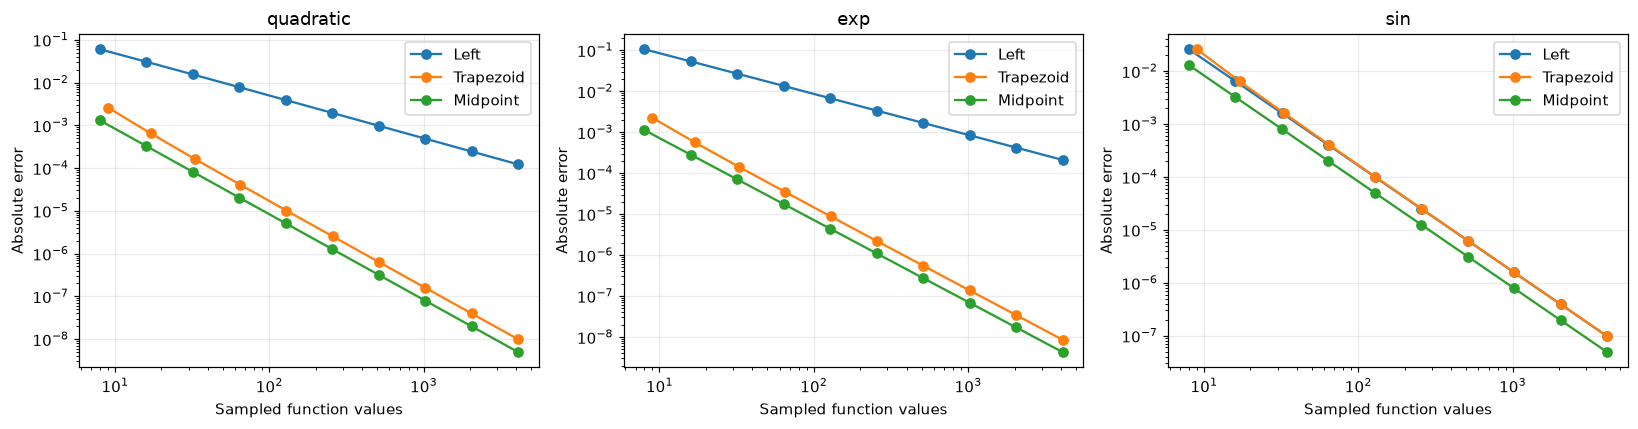

In [8]:
integral_cases = [
    ("quadratic", lambda x: x*x, 0.0, 1.0, 1/3, 2.0, 2.0),
    ("exp", np.exp, 0.0, 1.0, np.e-1, np.e, np.e),
    ("sin", np.sin, 0.0, np.pi, 2.0, 1.0, 1.0),
]
integral_methods = [("Left", left_rectangle), ("Trapezoid", trapezoid), ("Midpoint", midpoint)]
counts = 2**np.arange(3, 13)
integral_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, function, a, b, reference, m1, m2) in zip(axes, integral_cases):
    for method_name, method in integral_methods:
        errors = []
        for count in counts:
            approximation = method(function, a, b, int(count))
            error = abs(approximation - reference)
            evaluations = int(count) + (method_name == "Trapezoid")
            integral_rows.append(dict(case=name, method=method_name, intervals=int(count),
                                      sampled_values=evaluations, approximation=approximation,
                                      absolute_error=error))
            errors.append(error)
            h = (b-a)/count
            bound = ((b-a)*m1*h/2 if method_name == "Left" else
                     (b-a)*m2*h*h/(24 if method_name == "Midpoint" else 12))
            assert error <= bound + 1e-12
        ax.loglog(counts + (method_name == "Trapezoid"), errors, "o-", label=method_name)
        slope = observed_order(1/counts[-5:], errors[-5:])
        order_rows.append(dict(kind="integral", case=name, method=method_name, measured_order=slope))
        print(f"{name:10} {method_name:10} estimated order={slope:.3f}; final error={errors[-1]:.3e}")
    ax.set(title=name, xlabel="Sampled function values", ylabel="Absolute error")
    ax.legend()
finish_figure(fig, "integral_errors.png")
save_rows("integral_errors.csv", integral_rows)
save_rows("convergence_orders.csv", order_rows)


### An exception: symmetry changes the comparison
On [0,π], sin(x) has zero endpoint values. Therefore $T_n-L_n=h(f(b)-f(a))/2$ vanishes in exact arithmetic. Both methods return the same approximation even though their general error bounds have different orders. The measured second-order convergence of left rectangles here is a special cancellation, not a contradiction of its first-order general bound. In float64, sin(π) is only approximately zero.


In [9]:
for count in (8, 64, 512):
    assert np.isclose(left_rectangle(np.sin, 0, np.pi, count),
                      trapezoid(np.sin, 0, np.pi, count), atol=1e-14, rtol=0)
print("Endpoint-cancellation example verified.")


Endpoint-cancellation example verified.


### 6.1 Equal-cost comparison and a tolerance budget
Equal interval counts give trapezoids one extra endpoint sample. To compare exactly equal sampled-value budgets B, use B intervals for left rectangles and midpoints, but B−1 intervals for trapezoids. The cost is scalar function values, not the number of vectorized Python calls. Memory and runtime are not measured directly.

For exp on [0,1], we also ask which tested budget first meets absolute-error targets $10^{-3}$, $10^{-5}$, and $10^{-7}$. A missing result means **not reached on the tested grid**, not impossible. These targets are assessed with a known analytical answer; this is not an adaptive stopping rule for an unknown integral. Searching all candidate budgets also has a cost that the per-estimate budget excludes.

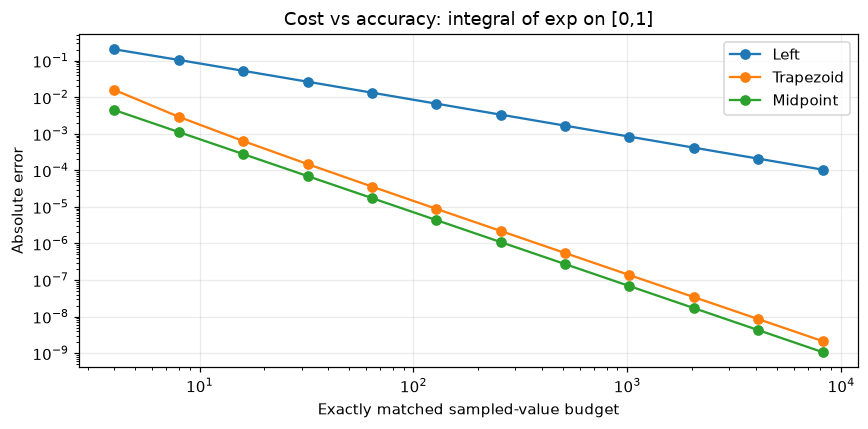

{'target': 0.001, 'method': 'Left', 'sampled_values': 1024, 'absolute_error': 0.0008388682422837412}
{'target': 0.001, 'method': 'Trapezoid', 'sampled_values': 16, 'absolute_error': 0.0006363535414044552}
{'target': 0.001, 'method': 'Midpoint', 'sampled_values': 16, 'absolute_error': 0.0002796364063848422}
{'target': 1e-05, 'method': 'Left', 'sampled_values': 'not reached', 'absolute_error': 'not reached'}
{'target': 1e-05, 'method': 'Trapezoid', 'sampled_values': 128, 'absolute_error': 8.877798029161e-06}
{'target': 1e-05, 'method': 'Midpoint', 'sampled_values': 128, 'absolute_error': 4.369808882520587e-06}
{'target': 1e-07, 'method': 'Left', 'sampled_values': 'not reached', 'absolute_error': 'not reached'}
{'target': 1e-07, 'method': 'Trapezoid', 'sampled_values': 2048, 'absolute_error': 3.417255611815051e-08}
{'target': 1e-07, 'method': 'Midpoint', 'sampled_values': 1024, 'absolute_error': 6.827838339162895e-08}


In [10]:
from analysis_tools import observed_order, first_budget_meeting
budgets = 2**np.arange(2, 14)
cost_rows = []
fig, ax = plt.subplots(figsize=(8, 4))
for label, method in integral_methods:
    measured_errors = []
    for budget in budgets:
        intervals = int(budget) - (label == "Trapezoid")
        calls = []
        def counted_exp(nodes):
            calls.append(np.size(nodes))
            return np.exp(nodes)
        estimate = method(counted_exp, 0, 1, intervals)
        assert sum(calls) == budget
        error = abs(estimate - (np.e-1))
        measured_errors.append(error)
        cost_rows.append(dict(method=label, intervals=intervals,
                              sampled_values=int(budget), absolute_error=error))
    ax.loglog(budgets, measured_errors, "o-", label=label)
ax.set(xlabel="Exactly matched sampled-value budget", ylabel="Absolute error", title="Cost vs accuracy: integral of exp on [0,1]")
ax.legend()
finish_figure(fig, "cost_accuracy.png")
save_rows("cost_accuracy.csv", cost_rows)
tolerance_rows = []
for target in (1e-3, 1e-5, 1e-7):
    for label, _ in integral_methods:
        best = first_budget_meeting([row for row in cost_rows if row["method"] == label], target)
        row = dict(target=target, method=label,
                   sampled_values=best["sampled_values"] if best else "not reached",
                   absolute_error=best["absolute_error"] if best else "not reached")
        tolerance_rows.append(row)
        print(row)
save_rows("tolerance_budgets.csv", tolerance_rows)


## 7. Application: estimating velocity and distance
Consider a model position $s(t)=t^3$ metres for time in seconds on [0,2]. Velocity is $v(t)=3t^2$ m/s and acceleration is $6t$ m/s². We estimate velocity at t=1, then recover displacement by integrating velocity over [0,2]. Velocity is nonnegative, so displacement equals distance here. The exact distance is 8 m.

This is a controlled synthetic motion model, not experimental sensor data. It connects the numerical question to a practical rate/accumulation task while retaining a known answer.


The motion model has nonconstant acceleration, so the integration experiment is more informative than a constant-velocity example. It remains an idealized known trajectory; no conclusions about real sensor calibration are inferred.

Velocity at t=1, exact: 3 m/s
Forward estimate: 3.0301000000000133
Central estimate: 3.0001000000000055
n=  10: left=6.84000000 m; trapezoid=8.04000000 m; exact=8 m
n= 100: left=7.88040000 m; trapezoid=8.00040000 m; exact=8 m
n=1000: left=7.98800400 m; trapezoid=8.00000400 m; exact=8 m


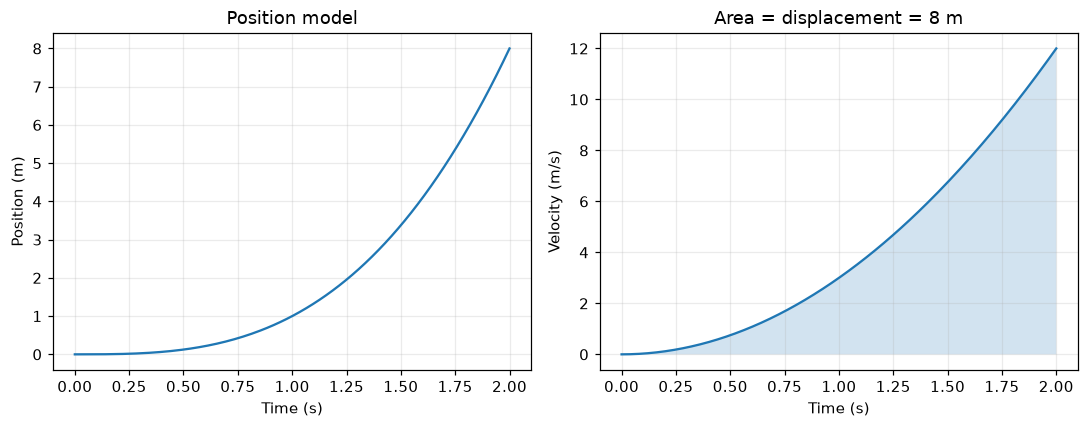

In [11]:
position = lambda t: t**3
velocity = lambda t: 3*t*t
print("Velocity at t=1, exact: 3 m/s")
print("Forward estimate:", forward_difference(position, 1.0, 0.01))
print("Central estimate:", central_difference(position, 1.0, 0.01))
application_rows = []
for count in (10, 100, 1000):
    left = left_rectangle(velocity, 0, 2, count)
    trap = trapezoid(velocity, 0, 2, count)
    application_rows.append(dict(intervals=count, left_distance=left, trapezoid_distance=trap,
                                 left_error=abs(left-8), trapezoid_error=abs(trap-8)))
    print(f"n={count:4}: left={left:.8f} m; trapezoid={trap:.8f} m; exact=8 m")
save_rows("motion_application.csv", application_rows)
t = np.linspace(0, 2, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(t, position(t))
axes[0].set(xlabel="Time (s)", ylabel="Position (m)", title="Position model")
axes[1].plot(t, velocity(t))
axes[1].fill_between(t, velocity(t), alpha=0.2)
axes[1].set(xlabel="Time (s)", ylabel="Velocity (m/s)", title="Area = displacement = 8 m")
finish_figure(fig, "motion_application.png")


## 8. Limitations: noisy samples and nonsmooth functions
Differentiation amplifies measurement noise. For independent additive sample errors with variance σ², the noise variance of a central difference is σ²/(2h²); shrinking h increases the noise contribution. This follows by adding the variances of the two sample errors and dividing by (2h)². The smooth deterministic experiments above do not quantify a complete sensor pipeline.

A second limitation is differentiability: applying the symmetric formula to abs(x) at zero returns zero for every positive step, even though the true derivative does not exist. Agreement across step sizes alone is insufficient validation. Integration convergence claims likewise require regularity; singular or discontinuous functions need separate treatment.


### 8.1 Quantifying the cost of higher-order differentiation under noise
For an estimator $h^{-1}\sum_i w_i y_i$ and independent zero-mean sample noise with variance $\sigma^2$, variance propagation gives $\operatorname{Var}(D)=\sigma^2\sum_i w_i^2/h^2$.

Central weights on the four nodes [−h, −h/2, h/2, h] are [−1/2, 0, 0, 1/2]. Richardson weights are [1/6, −4/3, 4/3, −1/6]. Therefore central variance is $\sigma^2/(2h^2)$ and Richardson variance is $65\sigma^2/(18h^2)$: about 7.22 times larger at the **same outer step h**. A fair globally optimized comparison could choose different steps; we do not infer a universal ranking.

The following simulation uses 20,000 independent draws per step and a fixed seed. It compares measured RMSE to $\sqrt{\text{bias}^2+\operatorname{Var}(D)}$. Its standard-deviation ratio checks the model without confusing truncation bias with noise spread. Gaussian independent noise is an assumption; correlated or biased measurements require a covariance model.


Symmetric estimate for abs at 0: 0.0
The derivative does not exist: one-sided slopes are -1 and +1.


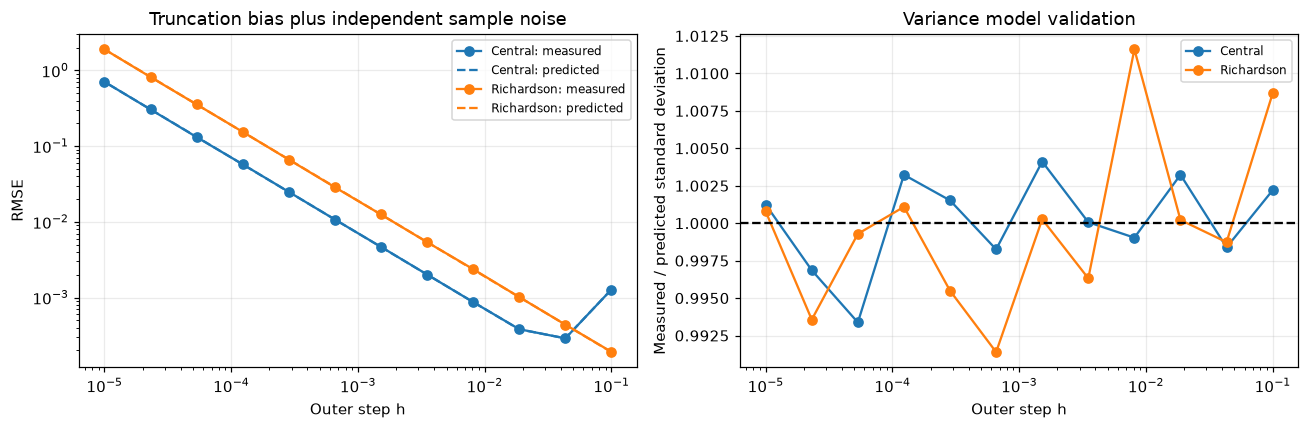

All Monte Carlo standard-deviation ratios are within 5% of the independent-noise model.


In [12]:
print("Symmetric estimate for abs at 0:", central_difference(np.abs, 0.0, 0.01))
print("The derivative does not exist: one-sided slopes are -1 and +1.")
from analysis_tools import noise_standard_deviation
rng = np.random.default_rng(2026)
noise_steps = np.logspace(-1, -5, 12)
sigma = 1e-5
trials = 20000
weights_by_method = {
    "Central": np.array([-0.5, 0, 0, 0.5]),
    "Richardson": np.array([1/6, -4/3, 4/3, -1/6]),
}
noise_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, weights in weights_by_method.items():
    empirical_rmse, predicted_rmse, ratios = [], [], []
    for h in noise_steps:
        nodes = 0.7 + h*np.array([-1, -0.5, 0.5, 1])
        clean = np.sin(nodes)
        deterministic_estimate = np.dot(clean, weights)/h
        bias = deterministic_estimate - np.cos(0.7)
        estimates = (clean + rng.normal(0, sigma, (trials, 4))) @ weights / h
        measured_sd = np.std(estimates, ddof=1)
        predicted_sd = noise_standard_deviation(weights, sigma, h)
        rmse = np.sqrt(np.mean((estimates-np.cos(0.7))**2))
        model_rmse = np.sqrt(bias*bias + predicted_sd*predicted_sd)
        ratio = measured_sd/predicted_sd
        assert abs(ratio-1) < 0.05
        empirical_rmse.append(rmse)
        predicted_rmse.append(model_rmse)
        ratios.append(ratio)
        noise_rows.append(dict(method=label, step=h, trials=trials, sigma=sigma,
                               bias=bias, rmse=rmse, predicted_rmse=model_rmse,
                               measured_sd=measured_sd, predicted_sd=predicted_sd,
                               sd_ratio=ratio))
    line, = axes[0].loglog(noise_steps, empirical_rmse, "o-", label=f"{label}: measured")
    axes[0].loglog(noise_steps, predicted_rmse, "--", color=line.get_color(), label=f"{label}: predicted")
    axes[1].semilogx(noise_steps, ratios, "o-", label=label)
axes[0].set(xlabel="Outer step h", ylabel="RMSE", title="Truncation bias plus independent sample noise")
axes[1].axhline(1, color="black", linestyle="--")
axes[1].set(xlabel="Outer step h", ylabel="Measured / predicted standard deviation", title="Variance model validation")
for ax in axes:
    ax.legend(fontsize=8)
finish_figure(fig, "noise_sensitivity.png")
save_rows("noise_experiment.csv", noise_rows)
print("All Monte Carlo standard-deviation ratios are within 5% of the independent-noise model.")


### 8.2 Domain boundaries and loss of smoothness
For log(x), the domain is x>0. At x=0.01 and h=0.02 a central or Richardson formula would evaluate outside that domain. The implementation rejects the non-finite sample. Forward differences stay within the domain here, though a large valid step can still be inaccurate. Reducing h below the distance to the boundary permits symmetric sampling. None of this automatically selects the best method for an arbitrary unknown function.

For integration, sqrt(x) on [0,1] has the finite integral 2/3, but its derivatives are unbounded near zero. The second-derivative error bounds used for the smooth benchmarks do not apply. We measure convergence separately rather than claiming guaranteed second-order accuracy. Trapezoids and midpoints approach order 1.5 in this example. This is a specific observation, not a theorem for every nonsmooth integrand.

{'method': 'Forward', 'step': 0.02, 'status': 'finite estimate', 'absolute_error': 45.06938556659455}
{'method': 'Central', 'step': 0.02, 'status': 'rejected invalid sample', 'absolute_error': 'not applicable'}
{'method': 'Richardson', 'step': 0.02, 'status': 'rejected invalid sample', 'absolute_error': 'not applicable'}
{'method': 'Forward', 'step': 0.005, 'status': 'finite estimate', 'absolute_error': 18.906978378367256}
{'method': 'Central', 'step': 0.005, 'status': 'finite estimate', 'absolute_error': 9.861228866810904}
{'method': 'Richardson', 'step': 0.005, 'status': 'finite estimate', 'absolute_error': 0.4002432846726123}
{'method': 'Forward', 'step': 0.001, 'status': 'finite estimate', 'absolute_error': 4.689820195675239}
{'method': 'Central', 'step': 0.001, 'status': 'finite estimate', 'absolute_error': 0.3353477310757711}
{'method': 'Richardson', 'step': 0.001, 'status': 'finite estimate', 'absolute_error': 0.00050450104885158}
{'method': 'Forward', 'step': 0.0001, 'status': 

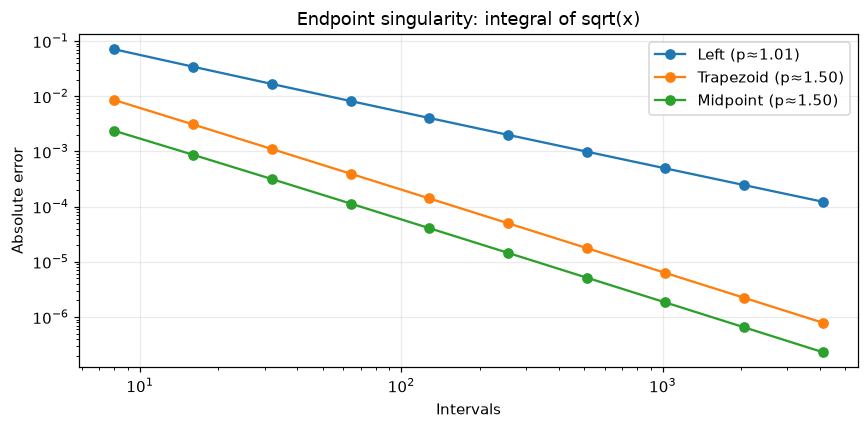

In [13]:
domain_rows = []
for h in (0.02, 0.005, 0.001, 0.0001):
    for label, method in derivative_methods + [("Richardson", richardson_difference)]:
        try:
            estimate = method(np.log, 0.01, h)
            row = dict(method=label, step=h, status="finite estimate", absolute_error=abs(estimate-100))
        except ValueError:
            row = dict(method=label, step=h, status="rejected invalid sample", absolute_error="not applicable")
        domain_rows.append(row)
        print(row)
save_rows("domain_boundaries.csv", domain_rows)
singular_counts = 2**np.arange(3, 13)
singular_rows, singular_orders = [], []
fig, ax = plt.subplots(figsize=(8, 4))
for label, method in integral_methods:
    errors = []
    for count in singular_counts:
        estimate = method(np.sqrt, 0, 1, int(count))
        error = abs(estimate-2/3)
        errors.append(error)
        singular_rows.append(dict(method=label, intervals=int(count), absolute_error=error))
    order = observed_order(1/singular_counts[-4:], errors[-4:])
    singular_orders.append(dict(method=label, measured_order=order))
    print(f"sqrt on [0,1], {label}: observed order={order:.3f}")
    ax.loglog(singular_counts, errors, "o-", label=f"{label} (p≈{order:.2f})")
ax.set(xlabel="Intervals", ylabel="Absolute error", title="Endpoint singularity: integral of sqrt(x)")
ax.legend()
finish_figure(fig, "endpoint_singularity.png")
save_rows("endpoint_singularity.csv", singular_rows)
save_rows("endpoint_orders.csv", singular_orders)


## 9. Results summary
The table below is generated from the actual experiments, so it remains consistent when the notebook is rerun. Estimated orders use the fixed fitting ranges described above.


Absolute error is used for comparison with known nonzero references. Noise RMSE averages over the independent Monte Carlo draws. Observed order fits use only the declared truncation-dominated or asymptotic ranges. A zero float64 error is not proof of exact arithmetic.

In [14]:
table = "| Experiment | Case | Method | Estimated order |\n|---|---|---|---:|\n"
for row in order_rows:
    table += f"| {row['kind']} | {row['case']} | {row['method']} | {row['measured_order']:.3f} |\n"
display(Markdown(table))
(OUTPUT / "measured_orders.md").write_text(table)

summary = "## Quantitative findings\n\n"
summary += "### Lowest tested sampled-value budgets for exp on [0,1]\n\n"
summary += "| Target absolute error | Method | Sampled values | Actual error |\n|---:|---|---:|---:|\n"
for row in tolerance_rows:
    value = row["absolute_error"]
    error_text = f"{value:.3e}" if isinstance(value, (float, np.floating)) else value
    summary += f"| {row['target']:.0e} | {row['method']} | {row['sampled_values']} | {error_text} |\n"
summary += "\nTargets are checked against the analytical result; unreached targets are censored at the tested maximum budget.\n\n"
summary += "### Endpoint singularity\n\n"
for row in singular_orders:
    summary += f"- sqrt(x), {row['method']}: fitted order {row['measured_order']:.3f}.\n"
max_variance_deviation = max(abs(row["sd_ratio"]-1) for row in noise_rows)
summary += f"\nMaximum Monte Carlo standard-deviation ratio deviation from the independent-noise model: {max_variance_deviation:.2%}.\n"
display(Markdown(summary))
(OUTPUT / "executive_summary.md").write_text(summary)


| Experiment | Case | Method | Estimated order |
|---|---|---|---:|
| derivative | exp at 1 | Forward | 1.001 |
| derivative | exp at 1 | Central | 2.000 |
| derivative | sin at 0.7 | Forward | 1.001 |
| derivative | sin at 0.7 | Central | 2.000 |
| derivative | cubic at 1.3 | Forward | 1.000 |
| derivative | cubic at 1.3 | Central | 2.000 |
| derivative | exp at 1 | Richardson | 4.001 |
| derivative | sin at 0.7 | Richardson | 3.999 |
| integral | quadratic | Left | 1.000 |
| integral | quadratic | Trapezoid | 2.000 |
| integral | quadratic | Midpoint | 2.000 |
| integral | exp | Left | 1.000 |
| integral | exp | Trapezoid | 2.000 |
| integral | exp | Midpoint | 2.000 |
| integral | sin | Left | 2.000 |
| integral | sin | Trapezoid | 2.000 |
| integral | sin | Midpoint | 2.000 |


## Quantitative findings

### Lowest tested sampled-value budgets for exp on [0,1]

| Target absolute error | Method | Sampled values | Actual error |
|---:|---|---:|---:|
| 1e-03 | Left | 1024 | 8.389e-04 |
| 1e-03 | Trapezoid | 16 | 6.364e-04 |
| 1e-03 | Midpoint | 16 | 2.796e-04 |
| 1e-05 | Left | not reached | not reached |
| 1e-05 | Trapezoid | 128 | 8.878e-06 |
| 1e-05 | Midpoint | 128 | 4.370e-06 |
| 1e-07 | Left | not reached | not reached |
| 1e-07 | Trapezoid | 2048 | 3.417e-08 |
| 1e-07 | Midpoint | 1024 | 6.828e-08 |

Targets are checked against the analytical result; unreached targets are censored at the tested maximum budget.

### Endpoint singularity

- sqrt(x), Left: fitted order 1.006.
- sqrt(x), Trapezoid: fitted order 1.497.
- sqrt(x), Midpoint: fitted order 1.495.

Maximum Monte Carlo standard-deviation ratio deviation from the independent-noise model: 1.16%.


892

## 10. Discussion and conclusion

### What the evidence supports
On the smooth derivative benchmarks, the preselected fitting ranges give orders near 1 for forward differences, 2 for central differences, and 4 for Richardson extrapolation. Richardson uses four sample values per estimate, versus two for the other derivatives. Its truncation improvement therefore comes with extra evaluation cost and, for the same outer step, stronger independent-noise amplification. Very small steps eventually encounter roundoff; an observed grid minimum is not a globally optimal recommendation.

For quadratic and exponential integrands, measured convergence is near order 1 for left rectangles and order 2 for trapezoids and midpoints. At matched sample budgets the higher-order methods reach tighter tolerances with fewer sampled values on the exponential benchmark. For example, on the tested power-of-two grid, a target absolute error of 10⁻⁷ is first met by 1,024 midpoint samples and 2,048 trapezoid samples. Left rectangles do not meet that target within the maximum 8,192 tested samples. These are empirical grid results with a known reference, not automatic stopping guarantees.

### Why a universal ranking would be misleading
For sin on [0,π], equal endpoint values cancel the difference between left rectangles and trapezoids; both converge quadratically. For sqrt(x), the bounded-second-derivative assumption fails at zero and trapezoids/midpoints approach order 1.5. For log near zero, symmetric derivative samples may leave the domain. For abs at zero, a symmetric numerical value of zero does not establish differentiability. Each exception has a mathematical explanation and prevents overgeneralizing the favorable benchmarks.

The motion example connects rates and accumulated quantities: differentiating position estimates velocity, and integrating nonnegative velocity recovers both displacement and distance. With 1,000 intervals, trapezoid integration gives 8.000004 m against the exact 8 m for this model. This independently checkable example is synthetic, not measured motion data.

The noise experiment propagates independent Gaussian sample uncertainty through the actual differentiation weights and compares predictions with 20,000 draws per step. It supports the predicted variance in this setting. Correlated, biased, or non-Gaussian sensor errors, and a jointly optimized step for each method, require further study. Absolute errors near float64 machine precision also depend on rounding in the analytical reference.

### Answer and practical choices
Choose a method whose sampling pattern and smoothness assumptions match the problem, validate on known cases, and examine the error-resolution tradeoff. Central differences are a useful interior-point baseline; Richardson is attractive for smooth low-noise functions when four samples are affordable. Trapezoids and midpoints are strong finite-interval baselines, with midpoint sampling useful when endpoint evaluations are unavailable. These are conditional recommendations within the tested setting, not promises for arbitrary functions.

### Further work
Adaptive quadrature, Simpson's rule, arbitrary-precision references, unequal sampling, and covariance-aware differentiation are possible extensions. They are not claimed as implemented. Timing benchmarks would require repeated measurements and control of vectorization and interpreter overhead; sampled-value counts alone do not establish wall-clock speed.

## 11. References and assistance disclosure
1. NIST Digital Library of Mathematical Functions, [§3.4 Differentiation](https://dlmf.nist.gov/3.4): general numerical differentiation formulas and error structure. Accessed 24 October 2026.
2. NIST Digital Library of Mathematical Functions, [§3.5(i) Trapezoidal Rules](https://dlmf.nist.gov/3.5#i): composite trapezoid formula and smoothness-dependent error bound. Accessed 24 October 2026.
3. NumPy documentation, [numpy.finfo](https://numpy.org/doc/stable/reference/generated/numpy.finfo.html): machine limits and epsilon.
4. SoftUni, Math Concepts for Developers, September 2026: supplied Calculus lecture, exercise notebook, and Final Exam Project Guidelines. These motivated the topic and the initial forward/central-difference and trapezoid work; the comparisons, additional methods, noise analysis, and application are organized specifically for this report.

The Taylor cancellations, midpoint bound, and independent-noise variance calculation are derived explicitly in the report. No external code repository was copied for the numerical algorithms. NumPy provides array operations and random sampling; Matplotlib provides plots; Jupyter tools execute and render the report. Assertions, a manifest, and isolated execution support reproducibility but do not prove correctness for every input.

**Assistance:** Codex assisted substantially with structure, mathematical exposition, implementation, validation, and editing. The student must review and understand the submitted work and follow any additional course assistance policy. The supplied guidelines prohibit plagiarism but do not state a separate AI policy. No instructor approval or completed student review is claimed. The provisional self-assessment in the repository remains for the student's review.
